In [35]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.compose import ColumnTransformer # applies preprocessing techniques
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer # fills in missing values
from sklearn.preprocessing import OneHotEncoder, StandardScaler 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

In [36]:
# pulls out week 3 decisions 
summary = json.load(open("02_run_summary.json"))
best_X, test_month = summary["best_X"], summary["test_month"]
low, high = summary["lower_threshold"], summary["upper_threshold"]

numeric_features = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet",
                    "YearBuilt", "Latitude", "Longitude", "ParkingTotal"]
categorical_features = ["PostalCode", "FireplaceYN", "NewConstructionYN", "City",
                        "CountyOrParish", "ViewYN", "MLSAreaMajor", "AttachedGarageYN"]
features = numeric_features + categorical_features
target = "ClosePrice"

# load cleaned dataset and split train/test sets
df = pd.read_csv("02_cleaned_data.csv", dtype={"PostalCode": "string"},
                 parse_dates=["CloseDate"], low_memory=False)
train = df[df["dataset_split"] == "train"].copy()
test = df[df["dataset_split"] == "test"].copy()

# converts values into text and replaces blanks with "missing" 
for d in (train, test):
    for c in categorical_features:
        d[c] = d[c].astype("string").fillna("Missing")

X_train, y_train = train[features], train[target].to_numpy(float)
X_test, y_test = test[features], test[target].to_numpy(float)

print(f"Training window: {best_X} months | test month: {test_month}")
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Training price bounds: ${low:,.0f} to ${high:,.0f}")

Training window: 9 months | test month: 2026-04
Train: (94162, 16) | Test: (12339, 16)
Training price bounds: $190,000 to $8,750,000


In [37]:
# re-build linear regression pipeline
#numeric columns fill gaps with median of column and rescale (sq ft and bedrooms) 
numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median")),
                                ("scaler", StandardScaler())])
categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
# routes numeric columns first then categorical columns
preprocessor = ColumnTransformer([("num", numeric_transformer, numeric_features),
                                  ("cat", categorical_transformer, categorical_features)])
# chaining preprocessing (cleaning/transforming features) and modeling into linear regression model
baseline_pipeline = Pipeline([("preprocessor", preprocessor), ("model", LinearRegression())])

In [38]:
# 1) most basic model (predict based off of median) - assumes every house costs same
pred_median = np.full(len(y_test), np.median(y_train))

# 2) predict using price/sq ft median
train_valid = train[train["LivingArea"] > 0]
median_ppsf = (train_valid["ClosePrice"] / train_valid["LivingArea"]).median()

# 3) predicted price is area * price/sq ft
pred_ppsf = (median_ppsf * test["LivingArea"]).fillna(train["ClosePrice"].median())
pred_ppsf = pred_ppsf.to_numpy()

In [39]:
# .fit trains the model based on log prices (ClosePrice heavily right skewed)
baseline_model = baseline_pipeline.fit(X_train, np.log(y_train))
# .predict produces log prices for test homes , exponentiating ensures positive prices
y_pred = np.exp(baseline_model.predict(X_test))   

assert np.isfinite(y_pred).all() and (y_pred > 0).all()
print("Encoded features:", baseline_model.named_steps["preprocessor"].get_feature_names_out().shape[0])

Encoded features: 3846


In [40]:
# metrics for the baseline and references
def metrics(y, p):
    # absolute percentage error
    ape = np.abs(p - y) / y * 100
    return {"n": len(y),
            "MdAPE_pct": np.median(ape),                
            "MAPE_pct": ape.mean(),
            "R2": r2_score(y, p),
            "MAE": mean_absolute_error(y, p),
            "RMSE": np.sqrt(np.mean((y - p) ** 2)),
            "within_10pct": (ape <= 10).mean() * 100, # share of home proces within 10% of real price
            "median_bias_pct": np.median((p - y) / y * 100)} # -1 values means model slightly underpredicts
# table to score all three baseline models
results = pd.DataFrame({
    "Reference: training median price": metrics(y_test, pred_median),
    "Reference: median $/sqft x living area": metrics(y_test, pred_ppsf),
    "Baseline: Linear Regression (log target)": metrics(y_test, y_pred)}).T
display(results.round(3))

,n,MdAPE_pct,MAPE_pct,R2,MAE,RMSE,within_10pct,median_bias_pct
Reference: training median price,12339.0,39.964,49.428,-0.128,614245.855,1054108.905,14.312,-3.836
Reference: median $/sqft x living area,12339.0,35.742,46.656,0.328,517385.154,813779.724,14.021,-3.534
Baseline: Linear Regression (log target),12339.0,9.996,14.026,0.758,197404.614,488106.025,50.004,-2.206


In [41]:
# compare scores from week 3 and validation scores with April test data
val_mdape = summary["validation_mean_MdAPE"]
test_mdape = results.loc["Baseline: Linear Regression (log target)", "MdAPE_pct"]
print(f"Validation mean MdAPE (Jan-Mar window selection): {val_mdape:.2f}%")
print(f"April test MdAPE:                                  {test_mdape:.2f}%")

Validation mean MdAPE (Jan-Mar window selection): 9.86%
April test MdAPE:                                  10.00%


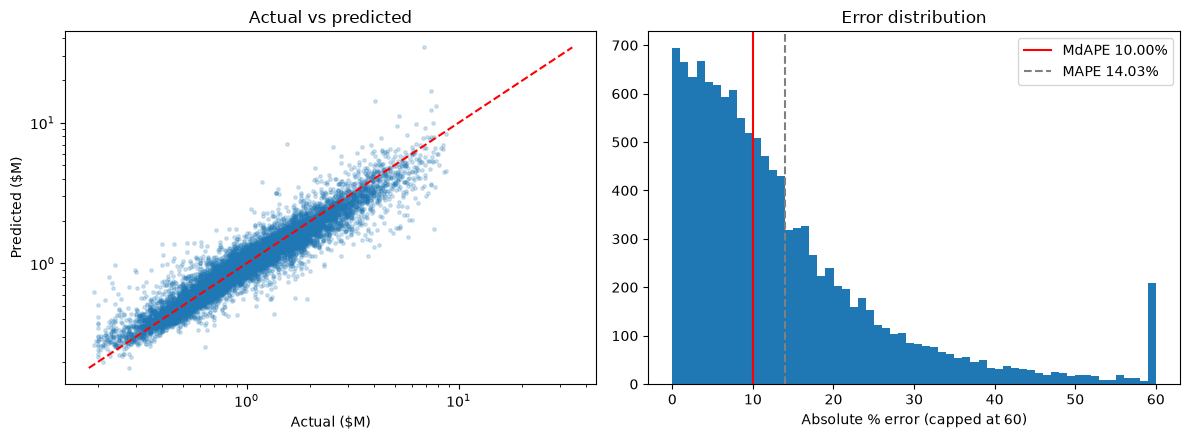

In [42]:
preds = test[["CloseDate", "City", "CountyOrParish", "PostalCode"]].copy()
preds["ActualClosePrice"] = y_test
preds["PredictedClosePrice"] = y_pred
preds["Residual"] = y_test - y_pred
preds["APE_pct"] = np.abs(y_pred - y_test) / y_test * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test / 1e6, y_pred / 1e6, s=6, alpha=0.2)
# plot prediction line with log axis
lim = [min(y_test.min(), y_pred.min()) / 1e6, max(y_test.max(), y_pred.max()) / 1e6]
ax[0].plot(lim, lim, "r--"); ax[0].set(xscale="log", yscale="log", xlabel="Actual ($M)",
                                       ylabel="Predicted ($M)", title="Actual vs predicted")

''' - histogram with price prediction percentage errors
    - x - axis percentage error
    - y - axis # houses in error range
    - ~half the predictions have errors below 9.98% (median error)
    - average absolute percentage error is 14.10%
'''
ax[1].hist(preds["APE_pct"].clip(upper=60), bins=60)
ax[1].axvline(preds["APE_pct"].median(), color="r", label=f"MdAPE {preds['APE_pct'].median():.2f}%")
ax[1].axvline(preds["APE_pct"].mean(), color="gray", ls="--", label=f"MAPE {preds['APE_pct'].mean():.2f}%")
ax[1].set(xlabel="Absolute % error (capped at 60)", title="Error distribution"); ax[1].legend()
fig.tight_layout(); plt.show()

In [43]:
# define function to split predictions into groups and compute values
def group_report(by):
    g = preds.groupby(by, observed=True)
    out = pd.DataFrame({"n": g.size(), "median_price": g["ActualClosePrice"].median(),
                        "MdAPE_pct": g["APE_pct"].median(), "MAPE_pct": g["APE_pct"].mean(),
                        "median_bias_pct": g.apply(lambda d: np.median((d.PredictedClosePrice - d.ActualClosePrice)
                                                                        / d.ActualClosePrice * 100))})
    return out

# divide groups inot 5 housing groups with aprox equal number of houses based on price
preds["price_quintile"] = pd.qcut(preds["ActualClosePrice"], 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"])
by_band = group_report("price_quintile")
# group by county
by_county = group_report("CountyOrParish").query("n >= 100").sort_values("n", ascending=False)
display(by_band.round(2)); display(by_county.round(2))

,n,median_price,MdAPE_pct,MAPE_pct,median_bias_pct
price_quintile,,,,,
Q1 low,2506,450000.0,9.42,15.36,2.53
Q2,2483,699000.0,8.35,11.73,-0.41
Q3,2503,925000.0,8.66,11.43,-0.32
Q4,2388,1333166.5,10.57,13.38,-4.62
Q5 high,2459,2350000.0,14.82,18.26,-10.80


,n,median_price,MdAPE_pct,MAPE_pct,median_bias_pct
CountyOrParish,,,,,
Los Angeles,3023,1020000.0,10.13,14.04,-1.97
Riverside,1879,638000.0,9.72,14.16,-0.84
San Diego,1448,1095000.0,10.46,14.26,-2.54
San Bernardino,1236,553000.0,8.49,12.03,-1.02
Orange,1177,1440000.0,9.41,12.94,-3.57
Alameda,590,1323000.0,13.10,16.33,-6.38
Contra Costa,584,900000.0,10.39,12.84,-3.28
Ventura,419,999009.0,9.21,13.80,-3.15
Santa Clara,406,1934500.0,10.83,14.61,-3.09


In [44]:
# Headline result 
b = results.loc["Baseline: Linear Regression (log target)"]
print("=" * 60)
print("WEEK 4 BASELINE: LINEAR REGRESSION (log target)")
print("=" * 60)
print(f"Training window : {best_X} months  |  test month: {test_month}")
print(f"Train rows      : {len(train):,}   |  test rows: {len(test):,}")
print(f"Price bounds    : ${low:,.0f} to ${high:,.0f}")
print(f"Encoded columns : {baseline_model.named_steps['preprocessor'].get_feature_names_out().shape[0]:,}")
print("-" * 60)
print(f"MdAPE (headline): {b['MdAPE_pct']:.2f}%")
print(f"R2              : {b['R2']:.4f}")
print(f"MAPE            : {b['MAPE_pct']:.2f}%")
print(f"MAE / RMSE      : ${b['MAE']:,.0f} / ${b['RMSE']:,.0f}")
print(f"Within 10%      : {b['within_10pct']:.1f}% of homes")
print(f"Median bias     : {b['median_bias_pct']:+.2f}%")
print(f"Validation MdAPE (Week 3, mean): {val_mdape:.2f}%")

# Baseline vs no-model references 
print("\nBASELINE VS NO-MODEL REFERENCES")
display(results.round(3))

# Error by price quintile and county
print("\nERROR BY PRICE QUINTILE")
display(by_band.round(2))
print("\nERROR BY COUNTY (100+ April sales)")
display(by_county.round(2))

# Sample of predictions (best, typical, worst)
print("\nSAMPLE PREDICTIONS")
sample = pd.concat([preds.nsmallest(3, "APE_pct"),
                    preds.iloc[(preds["APE_pct"] - preds["APE_pct"].median()).abs().argsort()[:3]],
                    preds.nlargest(3, "APE_pct")])
sample.insert(0, "case", ["best"] * 3 + ["typical"] * 3 + ["worst"] * 3)
display(sample[["case", "City", "CountyOrParish", "ActualClosePrice",
                "PredictedClosePrice", "APE_pct"]].round(1))

# Diagnostic plots 
plt.show()


WEEK 4 BASELINE: LINEAR REGRESSION (log target)
Training window : 9 months  |  test month: 2026-04
Train rows      : 94,162   |  test rows: 12,339
Price bounds    : $190,000 to $8,750,000
Encoded columns : 3,846
------------------------------------------------------------
MdAPE (headline): 10.00%
R2              : 0.7582
MAPE            : 14.03%
MAE / RMSE      : $197,405 / $488,106
Within 10%      : 50.0% of homes
Median bias     : -2.21%
Validation MdAPE (Week 3, mean): 9.86%

BASELINE VS NO-MODEL REFERENCES


,n,MdAPE_pct,MAPE_pct,R2,MAE,RMSE,within_10pct,median_bias_pct
Reference: training median price,12339.0,39.964,49.428,-0.128,614245.855,1054108.905,14.312,-3.836
Reference: median $/sqft x living area,12339.0,35.742,46.656,0.328,517385.154,813779.724,14.021,-3.534
Baseline: Linear Regression (log target),12339.0,9.996,14.026,0.758,197404.614,488106.025,50.004,-2.206



ERROR BY PRICE QUINTILE


,n,median_price,MdAPE_pct,MAPE_pct,median_bias_pct
price_quintile,,,,,
Q1 low,2506,450000.0,9.42,15.36,2.53
Q2,2483,699000.0,8.35,11.73,-0.41
Q3,2503,925000.0,8.66,11.43,-0.32
Q4,2388,1333166.5,10.57,13.38,-4.62
Q5 high,2459,2350000.0,14.82,18.26,-10.80



ERROR BY COUNTY (100+ April sales)


,n,median_price,MdAPE_pct,MAPE_pct,median_bias_pct
CountyOrParish,,,,,
Los Angeles,3023,1020000.0,10.13,14.04,-1.97
Riverside,1879,638000.0,9.72,14.16,-0.84
San Diego,1448,1095000.0,10.46,14.26,-2.54
San Bernardino,1236,553000.0,8.49,12.03,-1.02
Orange,1177,1440000.0,9.41,12.94,-3.57
Alameda,590,1323000.0,13.10,16.33,-6.38
Contra Costa,584,900000.0,10.39,12.84,-3.28
Ventura,419,999009.0,9.21,13.80,-3.15
Santa Clara,406,1934500.0,10.83,14.61,-3.09



SAMPLE PREDICTIONS


,case,City,CountyOrParish,ActualClosePrice,PredictedClosePrice,APE_pct
102933,best,Barstow,San Bernardino,325000.0,325006.9,0.0
101181,best,Fallbrook,San Diego,675000.0,675025.1,0.0
96288,best,El Cajon,San Diego,820000.0,820049.1,0.0
97111,typical,Pleasant Hill,Contra Costa,869000.0,955863.6,10.0
101345,typical,Big Bear,San Bernardino,425000.0,382521.3,10.0
101617,typical,Fairfield,Solano,730000.0,657043.2,10.0
98207,worst,Encino,Los Angeles,6835000.0,34337954.7,402.4
105914,worst,Granada Hills,Los Angeles,1550000.0,7059576.7,355.5
95416,worst,San Marcos,San Diego,240000.0,976064.9,306.7


In [46]:
# Save trained Linear Regression model for notebook 04
import joblib

joblib.dump(baseline_model, "03_baseline_model.joblib")

print("Baseline model saved successfully!")

Baseline model saved successfully!
